In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

# Afficher où on est actuellement
print(f"On est ici : {os.getcwd()}")

# Chercher les CSV là où ils sont vraiment
fichiers = glob.glob("*.csv")  # cherche dans le dossier actuel

print(f"\nFichiers trouvés : {len(fichiers)}")
for f in fichiers:
    print(f"  → {f}")

On est ici : C:\Users\SuperElectro\projet_immo\data\raw

Fichiers trouvés : 0


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

# Voir où on est
print(f"Dossier actuel : {os.getcwd()}")

# Lister TOUT ce qu'il y a dans ce dossier
print("\nFichiers présents :")
for f in os.listdir('.'):
    print(f"  → {f}")

Dossier actuel : C:\Users\SuperElectro\projet_immo\data\raw

Fichiers présents :
  → .ipynb_checkpoints
  → 01_EDA.ipynb
  → 75.csv.gz
  → 92.csv.gz
  → 94.csv.gz


In [7]:
# Charger les 3 fichiers CSV compressés
fichiers = ['75.csv.gz', '92.csv.gz', '94.csv.gz']

liste_df = []

for fichier in fichiers:
    print(f"Chargement : {fichier}...")
    df_temp = pd.read_csv(fichier, low_memory=False, compression='gzip')
    liste_df.append(df_temp)
    print(f"  → {len(df_temp):,} lignes chargées")

# Fusionner tout en un seul dataframe
dvf = pd.concat(liste_df, ignore_index=True)

print(f"\n✅ TOTAL : {len(dvf):,} lignes")
print(f"Colonnes : {len(dvf.columns)}")
print(f"\nNoms des colonnes :")
print(list(dvf.columns))

Chargement : 75.csv.gz...
  → 74,800 lignes chargées
Chargement : 92.csv.gz...
  → 58,663 lignes chargées
Chargement : 94.csv.gz...
  → 44,533 lignes chargées

✅ TOTAL : 177,996 lignes
Colonnes : 40

Noms des colonnes :
['id_mutation', 'date_mutation', 'numero_disposition', 'nature_mutation', 'valeur_fonciere', 'adresse_numero', 'adresse_suffixe', 'adresse_nom_voie', 'adresse_code_voie', 'code_postal', 'code_commune', 'nom_commune', 'code_departement', 'ancien_code_commune', 'ancien_nom_commune', 'id_parcelle', 'ancien_id_parcelle', 'numero_volume', 'lot1_numero', 'lot1_surface_carrez', 'lot2_numero', 'lot2_surface_carrez', 'lot3_numero', 'lot3_surface_carrez', 'lot4_numero', 'lot4_surface_carrez', 'lot5_numero', 'lot5_surface_carrez', 'nombre_lots', 'code_type_local', 'type_local', 'surface_reelle_bati', 'nombre_pieces_principales', 'code_nature_culture', 'nature_culture', 'code_nature_culture_speciale', 'nature_culture_speciale', 'surface_terrain', 'longitude', 'latitude']


In [8]:
# Voir les 5 premières lignes
dvf.head()

,id_mutation,date_mutation,numero_disposition,nature_mutation,valeur_fonciere,adresse_numero,adresse_suffixe,adresse_nom_voie,adresse_code_voie,code_postal,...,type_local,surface_reelle_bati,nombre_pieces_principales,code_nature_culture,nature_culture,code_nature_culture_speciale,nature_culture_speciale,surface_terrain,longitude,latitude
0,2024-1193218,2024-01-04,1,Vente,1042000.0,4.0,NaN,VLA PERREUR,7288,75020.0,...,Appartement,86.0,4.0,NaN,NaN,NaN,NaN,NaN,2.405228,48.868216
1,2024-1193218,2024-01-04,1,Vente,1042000.0,4.0,NaN,VLA PERREUR,7288,75020.0,...,Dépendance,NaN,0.0,NaN,NaN,NaN,NaN,NaN,2.405228,48.868216
2,2024-1193218,2024-01-04,1,Vente,1042000.0,16.0,NaN,RUE DE LA DHUIS,2786,75020.0,...,Dépendance,NaN,0.0,NaN,NaN,NaN,NaN,NaN,2.405228,48.868216
3,2024-1193218,2024-01-04,1,Vente,1042000.0,16.0,NaN,RUE DE LA DHUIS,2786,75020.0,...,Dépendance,NaN,0.0,NaN,NaN,NaN,NaN,NaN,2.405228,48.868216
4,2024-1193218,2024-01-04,1,Vente,1042000.0,4.0,NaN,VLA PERREUR,7288,75020.0,...,Dépendance,NaN,0.0,NaN,NaN,NaN,NaN,NaN,2.405228,48.868216


In [9]:
# Filtres de base
dvf_filtre = dvf[
    (dvf['nature_mutation'] == 'Vente') &
    (dvf['type_local'].isin(['Maison', 'Appartement'])) &
    (dvf['valeur_fonciere'].notna()) &
    (dvf['surface_reelle_bati'].notna()) &
    (dvf['surface_reelle_bati'] > 0) &
    (dvf['valeur_fonciere'] > 0)
].copy()

print(f"Avant filtrage : {len(dvf):,} lignes")
print(f"Après filtrage : {len(dvf_filtre):,} lignes")
print(f"\nRépartition :")
print(dvf_filtre['type_local'].value_counts())

Avant filtrage : 177,996 lignes
Après filtrage : 67,340 lignes

Répartition :
type_local
Appartement    61990
Maison          5350
Name: count, dtype: int64


In [10]:
print("=== STATISTIQUES DES PRIX ===\n")

for type_bien in ['Maison', 'Appartement']:
    subset = dvf_filtre[dvf_filtre['type_local'] == type_bien]['valeur_fonciere']
    print(f"--- {type_bien} ---")
    print(f"  Nombre        : {len(subset):,}")
    print(f"  Prix minimum  : {subset.min():,.0f} €")
    print(f"  Prix médian   : {subset.median():,.0f} €")
    print(f"  Prix moyen    : {subset.mean():,.0f} €")
    print(f"  Prix maximum  : {subset.max():,.0f} €")
    print()

=== STATISTIQUES DES PRIX ===

--- Maison ---
  Nombre        : 5,350
  Prix minimum  : 1 €
  Prix médian   : 575,000 €
  Prix moyen    : 915,844 €
  Prix maximum  : 58,000,000 €

--- Appartement ---
  Nombre        : 61,990
  Prix minimum  : 1 €
  Prix médian   : 385,000 €
  Prix moyen    : 2,676,394 €
  Prix maximum  : 255,000,000 €



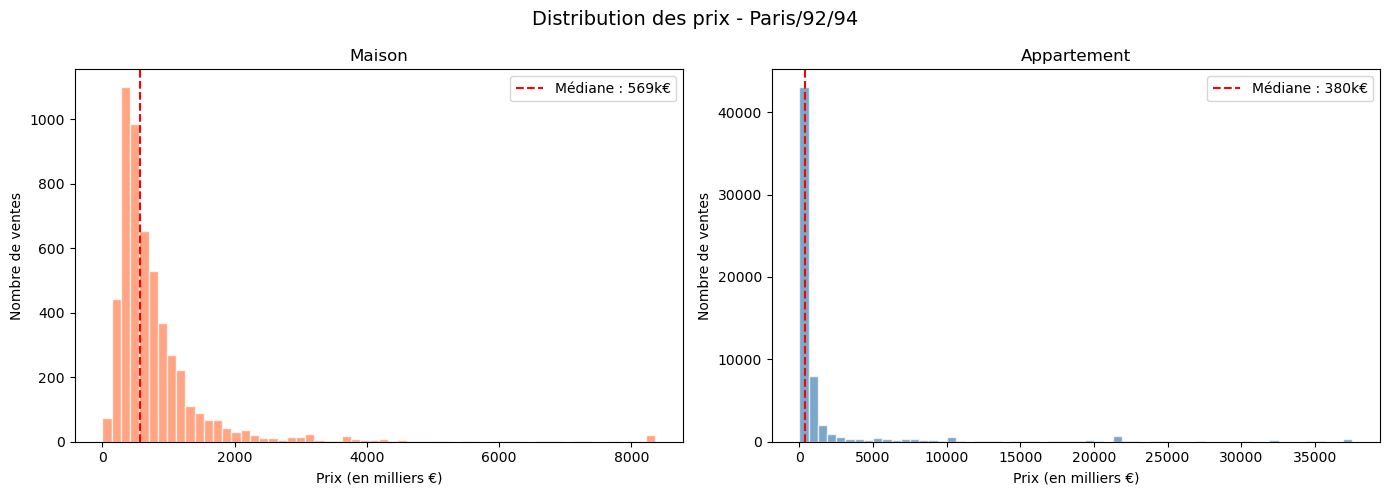

✅ Graphique affiché


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Distribution des prix - Paris/92/94', fontsize=14)

for i, type_bien in enumerate(['Maison', 'Appartement']):
    subset = dvf_filtre[dvf_filtre['type_local'] == type_bien]['valeur_fonciere']
    subset = subset[subset < subset.quantile(0.99)]
    
    axes[i].hist(subset / 1000, bins=60, 
                 color='steelblue' if type_bien == 'Appartement' else 'coral',
                 alpha=0.7, edgecolor='white')
    axes[i].set_title(f'{type_bien}')
    axes[i].set_xlabel('Prix (en milliers €)')
    axes[i].set_ylabel('Nombre de ventes')
    axes[i].axvline(subset.median()/1000, color='red',
                    linestyle='--', 
                    label=f'Médiane : {subset.median()/1000:,.0f}k€')
    axes[i].legend()

plt.tight_layout()
plt.show()
print("✅ Graphique affiché")

In [12]:
dvf_filtre['departement'] = dvf_filtre['code_departement'].astype(str).str[:2]

noms_dept = {
    '75': 'Paris (75)',
    '92': 'Hauts-de-Seine (92)',
    '94': 'Val-de-Marne (94)'
}

prix_dept = dvf_filtre.groupby(
    ['departement', 'type_local']
)['valeur_fonciere'].median().reset_index()

prix_dept['departement_nom'] = prix_dept['departement'].map(noms_dept)
prix_dept['prix_k'] = prix_dept['valeur_fonciere'] / 1000

print("=== PRIX MÉDIAN PAR DÉPARTEMENT ===\n")
for _, row in prix_dept.iterrows():
    print(f"{row['departement_nom']:25s} | {row['type_local']:12s} | {row['prix_k']:,.0f}k€")

=== PRIX MÉDIAN PAR DÉPARTEMENT ===

Paris (75)                | Appartement  | 433k€
Paris (75)                | Maison       | 1,390k€
Hauts-de-Seine (92)       | Appartement  | 385k€
Hauts-de-Seine (92)       | Maison       | 780k€
Val-de-Marne (94)         | Appartement  | 275k€
Val-de-Marne (94)         | Maison       | 460k€


In [13]:
print("=== DONNÉES MANQUANTES ===\n")

colonnes = [
    'valeur_fonciere', 'surface_reelle_bati',
    'nombre_pieces_principales', 'surface_terrain',
    'code_departement', 'longitude', 'latitude', 'date_mutation'
]

for col in colonnes:
    nb = dvf_filtre[col].isna().sum()
    pct = nb / len(dvf_filtre) * 100
    statut = "✅" if pct < 5 else "⚠️" if pct < 30 else "❌"
    print(f"{statut} {col:35s} : {nb:,} manquants ({pct:.1f}%)")

=== DONNÉES MANQUANTES ===

✅ valeur_fonciere                     : 0 manquants (0.0%)
✅ surface_reelle_bati                 : 0 manquants (0.0%)
✅ nombre_pieces_principales           : 0 manquants (0.0%)
❌ surface_terrain                     : 54,939 manquants (81.6%)
✅ code_departement                    : 0 manquants (0.0%)
✅ longitude                           : 364 manquants (0.5%)
✅ latitude                            : 364 manquants (0.5%)
✅ date_mutation                       : 0 manquants (0.0%)


In [14]:
import os
os.makedirs('../processed', exist_ok=True)

dvf_filtre.to_csv('../processed/dvf_filtre.csv', index=False)
print(f"✅ Sauvegardé : {len(dvf_filtre):,} lignes")
print("→ Fichier : data/processed/dvf_filtre.csv")

✅ Sauvegardé : 67,340 lignes
→ Fichier : data/processed/dvf_filtre.csv


In [15]:
import pandas as pd
import numpy as np
import os

# Charger les données filtrées
df = pd.read_csv('../processed/dvf_filtre.csv', low_memory=False)
print(f"✅ Données chargées : {len(df):,} lignes")

# ============================================
# 1. SUPPRIMER LES PRIX ABERRANTS
# ============================================
avant = len(df)
df = df[(df['valeur_fonciere'] >= 20_000) & 
        (df['valeur_fonciere'] <= 5_000_000)]
print(f"\n1. Outliers prix supprimés : {avant - len(df):,} lignes")

# ============================================
# 2. SUPPRIMER LES SURFACES ABERRANTES
# ============================================
avant = len(df)
df = df[(df['surface_reelle_bati'] >= 5) & 
        (df['surface_reelle_bati'] <= 500)]
print(f"2. Outliers surface supprimés : {avant - len(df):,} lignes")

# ============================================
# 3. CALCULER LE PRIX AU M²
# ============================================
df['prix_m2'] = df['valeur_fonciere'] / df['surface_reelle_bati']

avant = len(df)
df = df[(df['prix_m2'] >= 1000) & (df['prix_m2'] <= 30_000)]
print(f"3. Prix/m² aberrants supprimés : {avant - len(df):,} lignes")

# ============================================
# 4. CORRIGER LES DONNÉES MANQUANTES
# ============================================
# surface_terrain : 0 pour les appartements
df['surface_terrain'] = df['surface_terrain'].fillna(0)

# longitude/latitude : remplacer par la médiane
df['longitude'] = df['longitude'].fillna(df['longitude'].median())
df['latitude']  = df['latitude'].fillna(df['latitude'].median())

print(f"4. Valeurs manquantes corrigées ✅")

# ============================================
# 5. CRÉER DE NOUVELLES COLONNES UTILES
# ============================================
# Extraire l'année et le trimestre de la date
df['date_mutation'] = pd.to_datetime(df['date_mutation'])
df['annee']     = df['date_mutation'].dt.year
df['trimestre'] = df['date_mutation'].dt.quarter

# Numéro de département
df['dept_num'] = df['code_departement'].astype(str).str[:2].astype(int)

# Prix médian au m² par département et type
prix_ref = df.groupby(['dept_num', 'type_local'])['prix_m2'].median()
df['prix_m2_ref_zone'] = df.apply(
    lambda r: prix_ref.get((r['dept_num'], r['type_local']), r['prix_m2']),
    axis=1
)

print(f"5. Nouvelles colonnes créées ✅")

# ============================================
# RÉSULTAT FINAL
# ============================================
print(f"\n{'='*40}")
print(f"DATASET FINAL : {len(df):,} lignes propres")
print(f"{'='*40}")
print(f"\nRépartition finale :")
print(df['type_local'].value_counts())

print(f"\nColonnes finales :")
colonnes_finales = ['type_local', 'valeur_fonciere', 'surface_reelle_bati',
                    'nombre_pieces_principales', 'surface_terrain',
                    'dept_num', 'longitude', 'latitude',
                    'annee', 'trimestre', 'prix_m2', 'prix_m2_ref_zone']
print(colonnes_finales)

# ============================================
# SAUVEGARDER
# ============================================
df_final = df[colonnes_finales].copy()
df_final.to_csv('../processed/dvf_clean.csv', index=False)
print(f"\n✅ Sauvegardé : data/processed/dvf_clean.csv")

✅ Données chargées : 67,340 lignes

1. Outliers prix supprimés : 7,605 lignes
2. Outliers surface supprimés : 19 lignes
3. Prix/m² aberrants supprimés : 2,997 lignes
4. Valeurs manquantes corrigées ✅
5. Nouvelles colonnes créées ✅

DATASET FINAL : 56,719 lignes propres

Répartition finale :
type_local
Appartement    51628
Maison          5091
Name: count, dtype: int64

Colonnes finales :
['type_local', 'valeur_fonciere', 'surface_reelle_bati', 'nombre_pieces_principales', 'surface_terrain', 'dept_num', 'longitude', 'latitude', 'annee', 'trimestre', 'prix_m2', 'prix_m2_ref_zone']

✅ Sauvegardé : data/processed/dvf_clean.csv
